In [1]:
# Importing Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

# Data Collection
df = pd.read_csv("Power_data.csv")
display(df.head())

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [2]:
# Train Test Split
X = df.drop("PE", axis=1)
y = df["PE"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Tensor Conversion
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

# Dataset  
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# DataLoader
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

In [3]:
# ANN Model Definition
class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()

        self.model = nn.Sequential(
            # 1st hidden layer
            nn.Linear(X_train.shape[1], 6),
            nn.ReLU(),
    
            # 2nd hidden layer
            nn.Linear(6, 6),
            nn.ReLU(),
    
            # output layer
            nn.Linear(6, 1),
        )

    def forward(self, x):
        return self.model(x)

In [4]:
model = ANN()
crietrion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [5]:
# Model Training
train_losses = []
val_losses = []

best_val_loss = float("inf")

epochs = 100

for epoch in range(epochs):
    model.train()
    running_loss = 0.0 # tot training loss for 1 epoch
    
    for xb, yb in train_loader:
        # xb = features of 1 batch
        # yb = labels of 1 batch
        optimizer.zero_grad()
        
        outputs = model(xb) # forward prop....predicted outputs for this batch
        loss = crietrion(outputs, yb) # compute loss
        loss.backward() # back prop.. compute gradients
        optimizer.step() # params update
        
        running_loss += loss.item() # loss is a tensor => py float

    epoch_train_loss = running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)


    # Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad(): # no gradients compute
        for xb, yb in test_loader:
            outputs = model(xb)
            loss = crietrion(outputs, yb)
            running_val_loss += loss

    epoch_val_loss = running_val_loss / len(test_loader)
    val_losses.append(epoch_val_loss)

    print(f"epoch {epoch+1}/{epochs} ==> train loss = {epoch_train_loss} & val loss = {epoch_val_loss}")

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), "model.pt")

epoch 1/100 ==> train loss = 206390.08723958334 & val loss = 205285.953125
epoch 2/100 ==> train loss = 202968.83151041667 & val loss = 199050.296875
epoch 3/100 ==> train loss = 191378.53528645833 & val loss = 179289.171875
epoch 4/100 ==> train loss = 161195.35891927083 & val loss = 140697.09375
epoch 5/100 ==> train loss = 121176.47887369791 & val loss = 102779.0078125
epoch 6/100 ==> train loss = 89643.09108072917 & val loss = 77575.15625
epoch 7/100 ==> train loss = 68428.03485514323 & val loss = 58786.05078125
epoch 8/100 ==> train loss = 50633.82206217448 & val loss = 41286.4609375
epoch 9/100 ==> train loss = 33638.462182617186 & val loss = 25097.2578125
epoch 10/100 ==> train loss = 18785.592635091147 & val loss = 12565.1123046875
epoch 11/100 ==> train loss = 9445.616072591145 & val loss = 6854.3564453125
epoch 12/100 ==> train loss = 5886.929708862304 & val loss = 4984.50830078125
epoch 13/100 ==> train loss = 4580.650025431315 & val loss = 4030.44921875
epoch 14/100 ==> tra

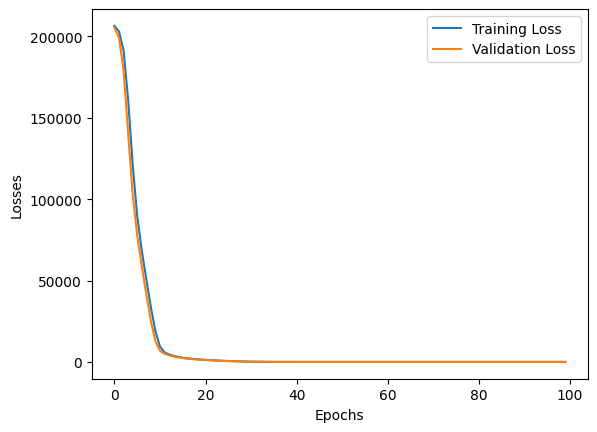

In [6]:
loss_df = pd.DataFrame({
    "Training Loss": train_losses,
    "Validation Loss": val_losses
})

plt.plot(loss_df["Training Loss"], label = "Training Loss")
plt.plot(loss_df["Validation Loss"], label = "Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

In [7]:
# Model Serialization
model.load_state_dict(torch.load("model.pt"))

<All keys matched successfully>

In [8]:
# Model Evaluation
model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = crietrion(train_preds, y_train_tensor)
    test_mse_loss = crietrion(test_preds, y_test_tensor)

print("Training MSE:", train_mse_loss.item())
print("Testing MSE:", test_mse_loss.item())
print("r^2 score =", r2_score(y_test, test_preds))

Training MSE: 20.752065658569336
Testing MSE: 18.90019416809082
r^2 score = 0.9339486965720546


In [9]:
# Model Prediction
predicted_df = pd.DataFrame(test_preds.numpy(), columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values, columns=["Actual Values"])
pd.concat([predicted_df, actual_df], axis=1)

,Predicted Values,Actual Values
0,435.318787,433.27
1,437.163757,438.16
2,461.008820,458.42
3,475.846771,480.82
4,435.453003,441.41
...,...,...
1909,451.228760,456.70
1910,431.836334,438.04
1911,467.223572,467.80
1912,431.329773,437.14
